# Generating dummy data

In [19]:
import numpy as np
x = np.linspace(0,4,20)
# model parameters
theta0 = 3.9654
theta1 = 2.5456
y1 = theta0+theta1*x
y1

array([ 3.9654    ,  4.50131579,  5.03723158,  5.57314737,  6.10906316,
        6.64497895,  7.18089474,  7.71681053,  8.25272632,  8.78864211,
        9.32455789,  9.86047368, 10.39638947, 10.93230526, 11.46822105,
       12.00413684, 12.54005263, 13.07596842, 13.61188421, 14.1478    ])

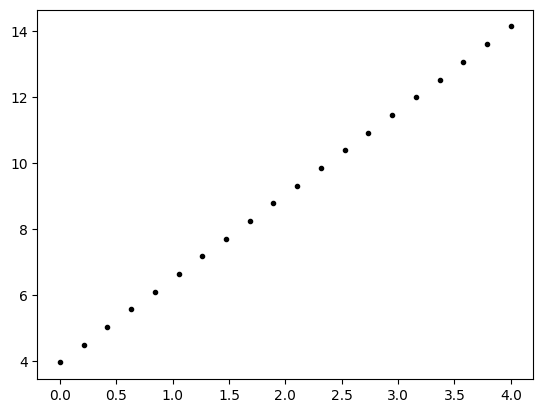

In [20]:
import matplotlib.pyplot as plt
plt.plot(x,y1,'.k')
plt.show()

# generating dummy data with noise

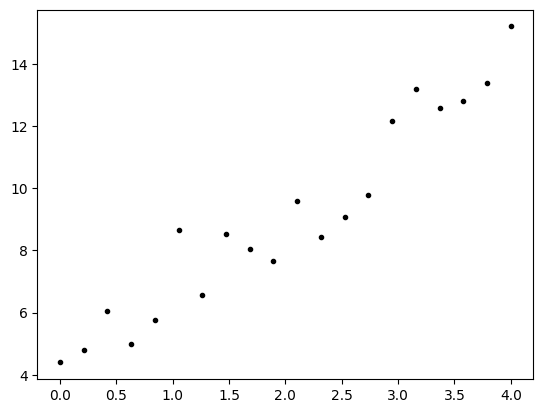

In [21]:
var = 1
y2 = theta0+theta1*x+var*np.random.randn(20)
plt.plot(x,y2,'.k')
plt.show()

# OLS implementation

$$\theta_0=\bar{y}-\theta_1\bar{x}$$

$$\theta_1 = \frac{\sum_{i=1}^n x^i(y^i-\bar{y})}{\sum_{i=1}^nx^i(x^i-\bar{x})}$$

In [28]:
#computing average values
sum = 0
for data in x:
    sum = data + sum
xMean = sum/len(x)
print(xMean)
x.mean()

2.0


np.float64(2.0)

In [30]:
def mean(x):
    sum = 0
    for data in x:
        sum = data + sum
    meanVal =sum/len(x)
    return meanVal

In [39]:
# test to obtain theta1
xMean = mean(x)
y1Mean = mean(y1)
y2Mean = mean(y2)
num = 0
den = 0 
for i in range(len(x)):
    num = num + x[i]* (y1[i] - y1Mean)
    den = den + x[i]* (x[i] - xMean)
num/den

np.float64(2.5456)

In [69]:
def ols(x,y):
    xAve = mean(x)
    yAve = mean(y)
    num = 0
    den = 0
    for i in range(len(x)):
        num = num + x[i]* (y[i] - yAve)
        den = den + x[i]* (x[i] - xAve)
    theta1H = num/den
    theta0H = yAve-theta1H*xAve
    return theta0H, theta1H

In [70]:
ols(x,y1)

(np.float64(3.9654), np.float64(2.5456))

In [62]:
# test to obtain theta1
xMean = mean(x)
y1Mean = mean(y1)
y2Mean = mean(y2)
num = 0
den = 0 
for a,b in zip(x,y1):
    num = num + a* (b - y1Mean)
    den = den + a* (a - xMean)
t1 = num/den
t0 = y1Mean-t1*xMean
print(t0, t1)

3.9654 2.5456


In [64]:
num2 = 0
den2 = 0
num2 = np.sum(x*(y1-y1.mean()))
den2 = np.sum(x*(x-x.mean()))
t1 = num2/den2
t1

np.float64(2.5456)

In [66]:
np.sum(x*(y1-y1.mean()))/np.sum(x*(x-x.mean()))

np.float64(2.5456)

# Comparing data and models

4.133363242256431 2.474808278679517


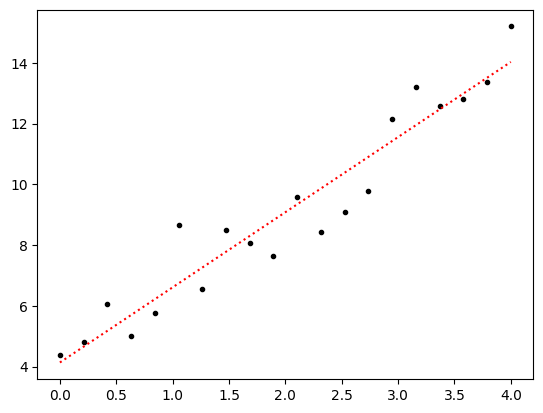

In [74]:
plt.plot(x,y2, '.k', label="Data")
t0H, t1H = ols(x,y2)
print(t0H, t1H)
yModel = t0H+t1H*x
plt.plot(x,yModel,':r', label="Model")
plt.show()